In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [25]:
df=pd.read_csv("train.csv")
df.head()

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
1,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,13 km/kg,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
2,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
3,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74
4,6,Nissan Micra Diesel XV,Jaipur,2013,86999,Diesel,Manual,First,23.08 kmpl,1461 CC,63.1 bhp,5.0,NaN,3.50


In [26]:
df.tail()

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
5842,6014,Maruti Swift VDI,Delhi,2014,27365,Diesel,Manual,First,28.4 kmpl,1248 CC,74 bhp,5.0,7.88 Lakh,4.75
5843,6015,Hyundai Xcent 1.1 CRDi S,Jaipur,2015,100000,Diesel,Manual,First,24.4 kmpl,1120 CC,71 bhp,5.0,NaN,4.00
5844,6016,Mahindra Xylo D4 BSIV,Jaipur,2012,55000,Diesel,Manual,Second,14.0 kmpl,2498 CC,112 bhp,8.0,NaN,2.90
5845,6017,Maruti Wagon R VXI,Kolkata,2013,46000,Petrol,Manual,First,18.9 kmpl,998 CC,67.1 bhp,5.0,NaN,2.65
5846,6018,Chevrolet Beat Diesel,Hyderabad,2011,47000,Diesel,Manual,First,25.44 kmpl,936 CC,57.6 bhp,5.0,NaN,2.50


In [27]:
df.shape

(5847, 14)

In [28]:
df.columns

Index(['Unnamed: 0', 'Name', 'Location', 'Year', 'Kilometers_Driven',
       'Fuel_Type', 'Transmission', 'Owner_Type', 'Mileage', 'Engine', 'Power',
       'Seats', 'New_Price', 'Price'],
      dtype='str')

In [29]:
df.describe()

,Unnamed: 0,Year,Kilometers_Driven,Seats,Price
count,5847.000000,5847.000000,5.847000e+03,5809.000000,5847.000000
mean,3013.181461,2013.448435,5.841013e+04,5.286452,9.653742
std,1736.398890,3.194949,9.237971e+04,0.806668,11.275966
min,1.000000,1998.000000,1.710000e+02,2.000000,0.440000
25%,1509.500000,2012.000000,3.346750e+04,5.000000,3.550000
50%,3015.000000,2014.000000,5.257600e+04,5.000000,5.750000
75%,4517.500000,2016.000000,7.249050e+04,5.000000,10.250000
max,6018.000000,2019.000000,6.500000e+06,10.000000,160.000000


In [30]:
df.isnull().sum()

Unnamed: 0              0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 2
Engine                 36
Power                  36
Seats                  38
New_Price            5032
Price                   0
dtype: int64

In [31]:
df.duplicated().sum()

np.int64(0)

In [32]:
df.drop(columns=['Unnamed: 0','New_Price'], inplace=True)

In [33]:
df.head()

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price
0,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,12.50
1,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,13 km/kg,1199 CC,88.7 bhp,5.0,4.50
2,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,6.00
3,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,17.74
4,Nissan Micra Diesel XV,Jaipur,2013,86999,Diesel,Manual,First,23.08 kmpl,1461 CC,63.1 bhp,5.0,3.50


In [34]:
df.to_csv("train_cleaned.csv", index=False)

EDA

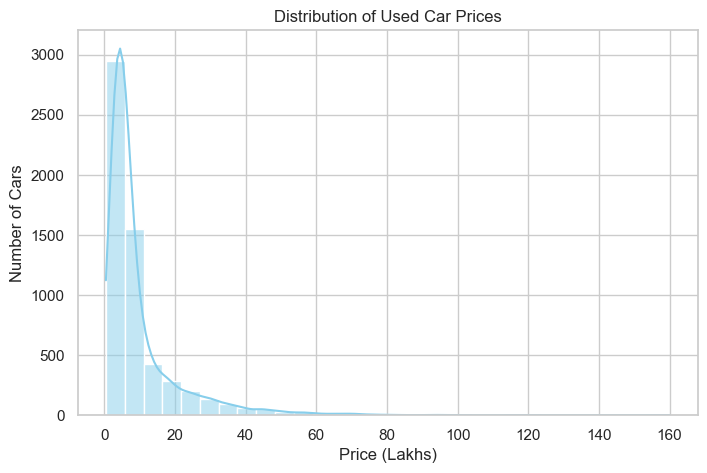

In [35]:
#distribution of used car prices
plt.figure(figsize=(8,5))

sns.histplot(df['Price'],
             bins=30,
             kde=True,
             color='skyblue')

plt.title("Distribution of Used Car Prices")
plt.xlabel("Price (Lakhs)")
plt.ylabel("Number of Cars")

plt.show()


most car prices are in lower range 

In [36]:
#feature engineering, extracting brand from name
df['Brand'] = df['Name'].str.split().str[0]

C:\Users\DELL\AppData\Local\Temp\ipykernel_17556\4267122813.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


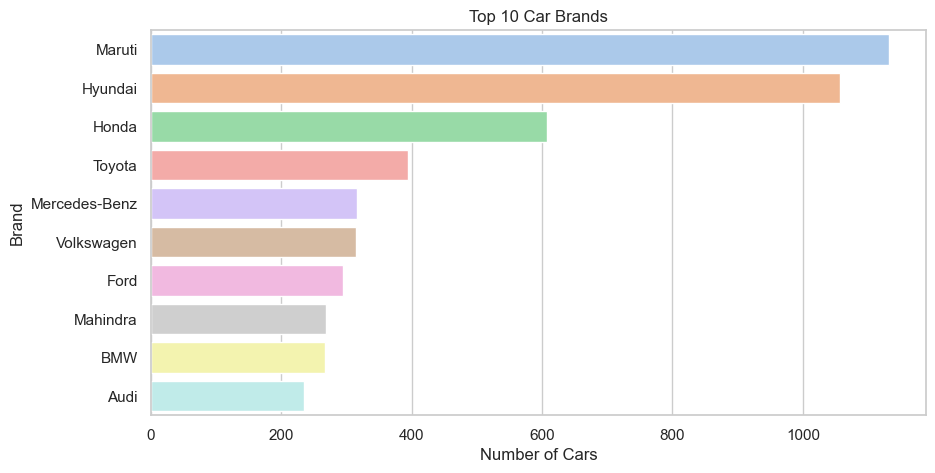

In [37]:
#top 10 car brands
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    y='Brand',
    order=df['Brand'].value_counts().head(10).index,
    palette='pastel'
)

plt.title("Top 10 Car Brands")
plt.xlabel("Number of Cars")
plt.ylabel("Brand")

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_17556\2030198713.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


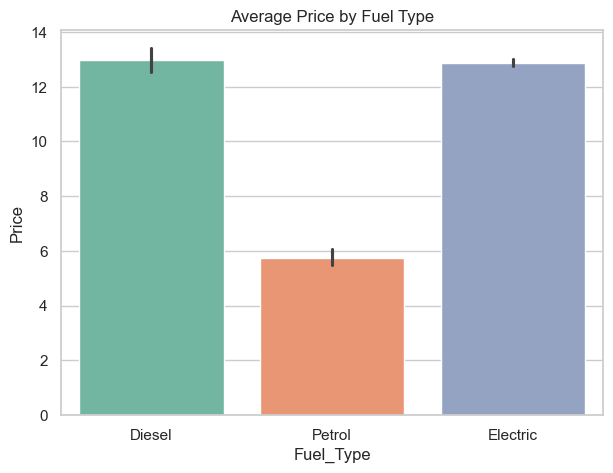

In [38]:
#avg price by fuel type
plt.figure(figsize=(7,5))

sns.barplot(
    data=df,
    x='Fuel_Type',
    y='Price',
    estimator='mean',
    palette='Set2'
)

plt.title("Average Price by Fuel Type")

plt.show()

car that use diesel and are electric have comparatively more price

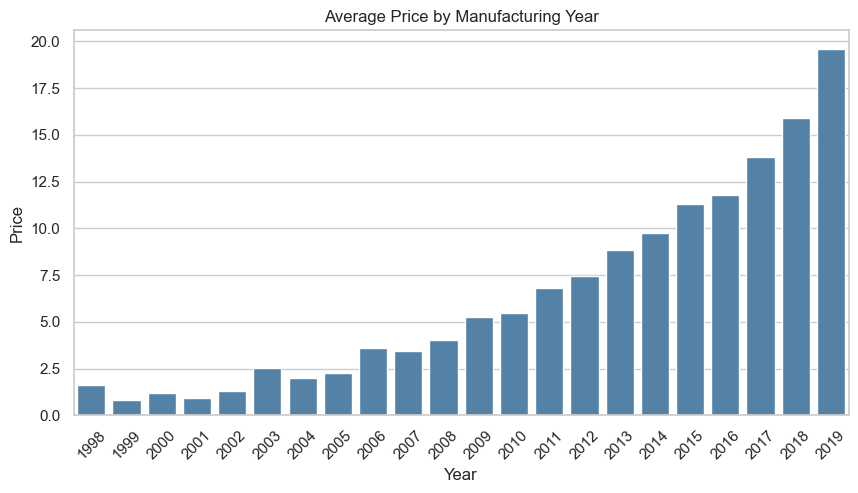

In [39]:
#price vs manufacturing year
avg_price = df.groupby('Year')['Price'].mean().reset_index()

plt.figure(figsize=(10,5))

sns.barplot(data=avg_price,
            x='Year',
            y='Price',
            color='steelblue')

plt.xticks(rotation=45)

plt.title("Average Price by Manufacturing Year")

plt.show()

newer cars have generally higher prices

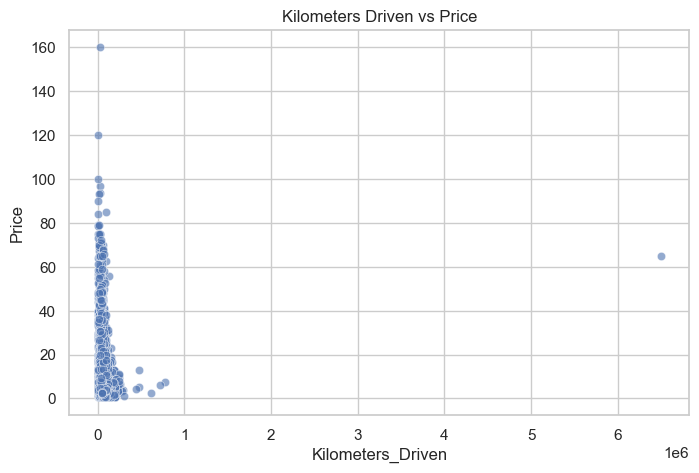

In [40]:
#mileage i.e. kilometer driven vs price
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='Kilometers_Driven',
    y='Price',
    alpha=0.6
)

plt.title("Kilometers Driven vs Price")

plt.show()

In [41]:
#converting categorical into numerical for corelation
eda = df.copy()

eda['Mileage'] = eda['Mileage'].str.extract('([\d.]+)').astype(float)

eda['Engine'] = eda['Engine'].str.extract('(\d+)').astype(float)

eda['Power'] = eda['Power'].str.extract('([\d.]+)').astype(float)

<>:4: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:4: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:8: SyntaxWarning: invalid escape sequence '\d'
C:\Users\DELL\AppData\Local\Temp\ipykernel_17556\2609093327.py:4: SyntaxWarning: invalid escape sequence '\d'
  eda['Mileage'] = eda['Mileage'].str.extract('([\d.]+)').astype(float)
C:\Users\DELL\AppData\Local\Temp\ipykernel_17556\2609093327.py:6: SyntaxWarning: invalid escape sequence '\d'
  eda['Engine'] = eda['Engine'].str.extract('(\d+)').astype(float)
C:\Users\DELL\AppData\Local\Temp\ipykernel_17556\2609093327.py:8: SyntaxWarning: invalid escape sequence '\d'
  eda['Power'] = eda['Power'].str.extract('([\d.]+)').astype(float)


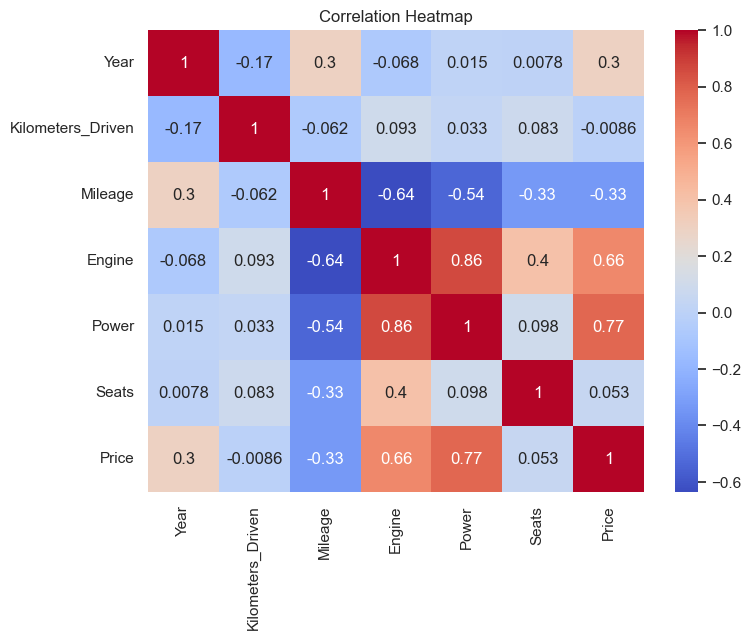

In [42]:
#correlation heatmap
plt.figure(figsize=(8,6))

sns.heatmap(
    eda.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

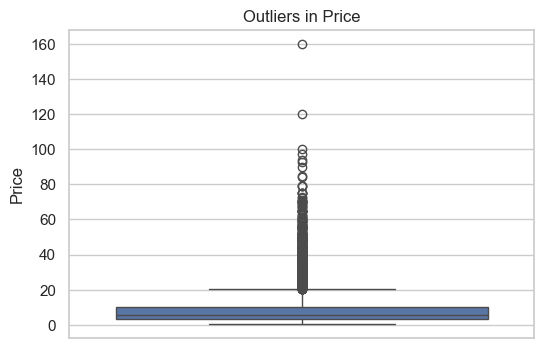

In [43]:
#outliear detection
plt.figure(figsize=(6,4))

sns.boxplot(y=df['Price'])

plt.title("Outliers in Price")

plt.show()

luxury car prices are shown as outliers

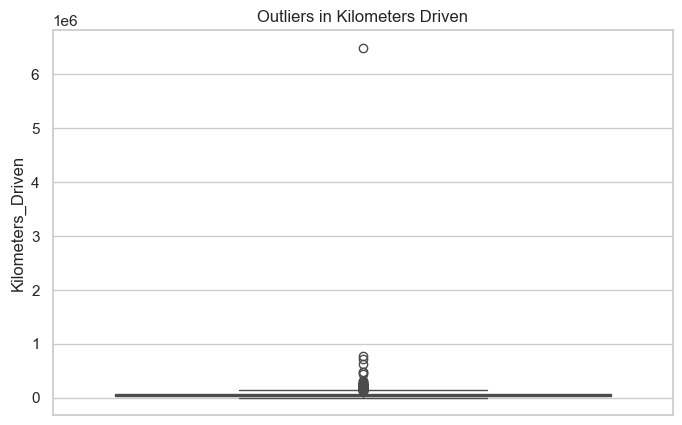

In [44]:
plt.figure(figsize=(8,5))

sns.boxplot(y=df['Kilometers_Driven'])

plt.title("Outliers in Kilometers Driven")

plt.show()

In [45]:
df.sort_values(by='Kilometers_Driven', ascending=False).head()

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price,Brand
2259,BMW X5 xDrive 30d M Sport,Chennai,2017,6500000,Diesel,Automatic,First,15.97 kmpl,2993 CC,258 bhp,5.0,65.0,BMW
326,Skoda Octavia Ambition Plus 2.0 TDI AT,Kolkata,2013,775000,Diesel,Automatic,First,19.3 kmpl,1968 CC,141 bhp,5.0,7.5,Skoda
1805,Volkswagen Vento Diesel Highline,Chennai,2013,720000,Diesel,Manual,First,20.54 kmpl,1598 CC,103.6 bhp,5.0,5.9,Volkswagen
344,Hyundai i10 Magna 1.2,Chennai,2009,620000,Petrol,Manual,First,20.36 kmpl,1197 CC,78.9 bhp,5.0,2.7,Hyundai
2997,Honda City i VTEC SV,Kolkata,2015,480000,Petrol,Manual,First,17.4 kmpl,1497 CC,117.3 bhp,5.0,5.0,Honda


In [46]:
#there is a outlier 65,00,000 km driven which is much likely to be a data entry error, this will be handle in machine learning pre processing stage